# Controle Digital - Exercícios 1 a 6
**Estruturas computacionais para implementação de sistemas em tempo discreto.**

Este notebook segue os quatro exemplos enviados do professor: `numpy`, vetores inicializados, laço `for` e `matplotlib`. No exercício 6, acrescenta-se apenas `time` para cronometrar.

O material da aula pede diagramas nos exercícios 1, 2 e 4, implementações nos exercícios 3 e 5 e medição de tempo no exercício 6. A implementação numérica do exercício 2 está no 3; a do 4 está no 5 e no 6. O exercício 1 fornece coeficientes simbólicos, sem valores para uma simulação numérica específica.

**Como usar:** abra este arquivo no Colab por **Arquivo > Fazer upload de notebook** e execute as células em ordem. Os resultados salvos foram gerados no ambiente de preparação deste material. Execute novamente no Colab para obter os seus próprios tempos.

**Condições adotadas:** sistemas causais, inicialmente em repouso. Para seguir o exemplo do professor, a entrada numérica é um degrau unitário precedido por amostras nulas. Essas amostras permitem usar os atrasos sem índices negativos. O eixo dos gráficos conta amostras a partir do início do degrau; não foi informado período de amostragem para convertê-lo em segundos.

Os laços terminam em `1000` para calcular até o índice `999`. Isso evita incluir no gráfico uma última amostra que permaneceu zerada por não ter sido calculada.

## Exercício 1 - Diagramas de blocos
### Equação 1
$$H(z)=\frac{a_0+a_1z^{-1}+a_2z^{-2}}{1+b_1z^{-1}+b_2z^{-2}}.$$
Multiplicando pelo denominador e aplicando a transformada Z inversa:
$$y[n]=a_0x[n]+a_1x[n-1]+a_2x[n-2]-b_1y[n-1]-b_2y[n-2].$$
Na forma direta I, há duas memórias de entrada e duas de saída; os ganhos de realimentação são **−b₁ e −b₂**.

Uma realização na forma direta II é:
$$w[n]=x[n]-b_1w[n-1]-b_2w[n-2],$$
$$y[n]=a_0w[n]+a_1w[n-1]+a_2w[n-2].$$
Aqui, as duas memórias de `w` são compartilhadas. Os diagramas completos estão no PDF que acompanha o notebook.

### Equação 2
$$H(z)=\sum_{k=0}^{11}h(k)z^{-k},\qquad y[n]=\sum_{k=0}^{11}h(k)x[n-k].$$
São **12 coeficientes e 11 atrasos unitários**. Em uma cadeia de atrasos, cada bloco deve ser $z^{-1}$; o sinal no segundo ponto de derivação já está atrasado de duas amostras.

Não foram atribuídos números a $a_i$, $b_i$ ou $h(k)$ porque o enunciado não fornece esses valores.

## Exercício 2 - Duas seções de segunda ordem em cascata
Os fatores conjugados obedecem a:
$$(1-re^{j\theta}z^{-1})(1-re^{-j\theta}z^{-1})=1-2r\cos(\theta)z^{-1}+r^2z^{-2}.$$
No numerador, $(1+jz^{-1})(1-jz^{-1})=1+z^{-2}$.

Assim, uma escolha válida é:
$$H_1(z)=\frac{1+z^{-2}}{1-\cos(\pi/4)z^{-1}+\frac14z^{-2}},$$
$$H_2(z)=\frac{1+z^{-1}}{1-\frac32\cos(\pi/8)z^{-1}+\frac9{16}z^{-2}},\qquad H(z)=H_1(z)H_2(z).$$
O numerador da segunda seção pode ser escrito como $1+z^{-1}+0z^{-2}$; ela é de segunda ordem pelo denominador.

Definindo $v[n]$ como a saída da primeira seção, a forma direta II de cada uma é:
$$w_1[n]=x[n]+\cos(\pi/4)w_1[n-1]-\tfrac14w_1[n-2],$$
$$v[n]=w_1[n]+w_1[n-2],$$
$$w_2[n]=v[n]+\tfrac32\cos(\pi/8)w_2[n-1]-\tfrac9{16}w_2[n-2],$$
$$y[n]=w_2[n]+w_2[n-1].$$
As quatro equações correspondem, na mesma ordem, às quatro linhas do laço a seguir.

## Exercício 3 - Implementação da cascata
São necessárias duas amostras iniciais nulas por causa dos atrasos de segunda ordem. As duas seções têm estados diferentes, `w1` e `w2`. O vetor `v` liga a saída da primeira à entrada da segunda.

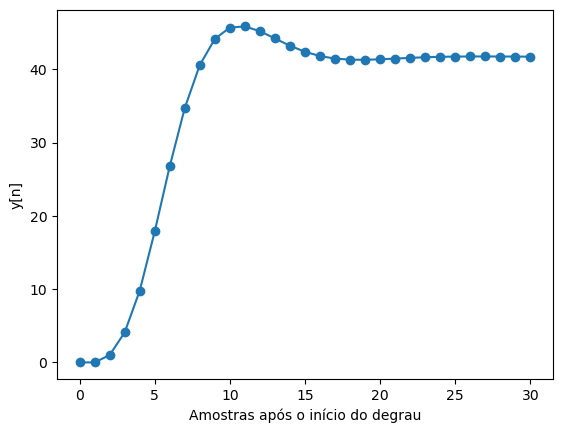

In [26]:
import numpy as np
import matplotlib.pyplot as plt

amostras = 100
w1 = np.zeros(amostras)
v = np.zeros(amostras)
w2 = np.zeros(amostras)
y = np.zeros(amostras)
x = np.ones(amostras)
x[0] = 0
x[1] = 0

c1 = np.cos(np.pi/4)
c2 = 1.5*np.cos(np.pi/8)

for i in range(0,amostras):
  w1[i] = x[i] + c1*w1[i-1] - 0.25*w1[i-2]
  v[i] = w1[i] + w1[i-2]
  w2[i] = v[i] + c2*w2[i-1] - 0.5625*w2[i-2]
  y[i] = w2[i] + w2[i-1]

plt.plot(y[:31], 'o-')
plt.xlabel('Amostras após o início do degrau')
plt.ylabel('y[n]')
plt.show()

**Conferência:** as primeiras seis saídas a partir do início do degrau são aproximadamente
`1; 4.092926; 9.773770; 17.863728; 26.774081; 34.714924`.
Como os polos têm módulos $0,5$ e $0,75$, a resposta causal é estável. Para o degrau unitário:
$$y[\infty]=H(1)=\frac{4}{(1-\cos(\pi/4)+1/4)(1-(3/2)\cos(\pi/8)+9/16)}\approx41{,}701959.$$
O pico transitório não precisa coincidir com esse valor final.

## Exercício 4 - Decomposição em paralelo
$$H(z)=\frac{4-\frac12z^{-1}-\frac12z^{-2}}{(1-\frac12z^{-1})(1+\frac12z^{-1})(1-\frac14z^{-1})}.$$
Escreva $q=z^{-1}$ e:
$$H(q)=\frac{A}{1-q/2}+\frac{B}{1+q/2}+\frac{C}{1-q/4}.$$
Eliminando os denominadores:
$$4-q/2-q^2/2=A(1+q/2)(1-q/4)+B(1-q/2)(1-q/4)+C(1-q/2)(1+q/2).$$
Em $q=2$, obtemos $A=1$; em $q=-2$, $B=1$; em $q=4$, $C=2$. Portanto:
$$H(z)=\frac{1}{1-\frac12z^{-1}}+\frac{1}{1+\frac12z^{-1}}+\frac{2}{1-\frac14z^{-1}}.$$

Cada ramo, em forma direta II de primeira ordem, tem uma memória:
$$w_1[n]=x[n]+\tfrac12w_1[n-1],\qquad y_1[n]=w_1[n],$$
$$w_2[n]=x[n]-\tfrac12w_2[n-1],\qquad y_2[n]=w_2[n],$$
$$w_3[n]=x[n]+\tfrac14w_3[n-1],\qquad y_3[n]=2w_3[n].$$
Todos recebem a mesma entrada. A saída é $y[n]=y_1[n]+y_2[n]+y_3[n]$.
No PDF, a decomposição é desenvolvida e os três ramos são desenhados.

## Exercício 5 - Implementação da forma paralela
Como cada ramo é de primeira ordem, basta uma amostra inicial nula. Atenção ao sinal negativo na segunda linha e ao ganho 2 do terceiro ramo.

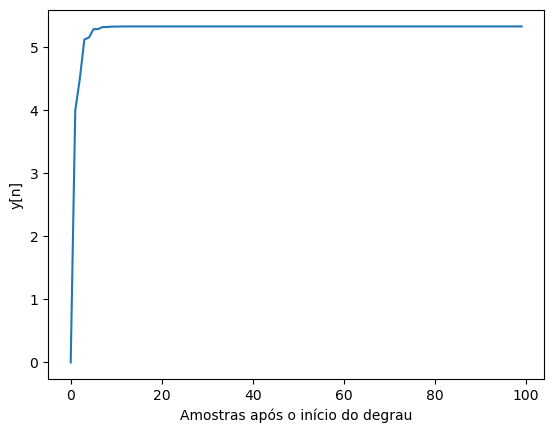

In [21]:
import numpy as np
import matplotlib.pyplot as plt

amostras = 100
w1 = np.zeros(amostras)
w2 = np.zeros(amostras)
w3 = np.zeros(amostras)
y = np.zeros(amostras)
x = np.ones(amostras)
x[0] = 0

for i in range(0,amostras):
  w1[i] = x[i] + 0.5*w1[i-1]
  w2[i] = x[i] - 0.5*w2[i-1]
  w3[i] = x[i] + 0.25*w3[i-1]
  y[i] = w1[i] + w2[i] + 2*w3[i]

plt.plot(y[0::])
plt.xlabel('Amostras após o início do degrau')
plt.ylabel('y[n]')
plt.show()

**Conferência:** as primeiras seis saídas são
`4; 4.5; 5.125; 5.15625; 5.2890625; 5.291015625`.
Para o degrau, o valor final é:
$$H(1)=\frac{1}{1-1/2}+\frac{1}{1+1/2}+\frac{2}{1-1/4}=\frac{16}{3}\approx5{,}333333.$$
Para uma conferência adicional com impulso, a resposta analítica é
$$h[n]=\left[(1/2)^n+(-1/2)^n+2(1/4)^n\right]u[n].$$
O código acima usa **degrau**, seguindo o modelo enviado; essa expressão de impulso é apenas uma referência matemática.

## Exercício 6 - Tempo de execução das três implementações
O denominador expandido é:
$$D(z)=1-\tfrac14z^{-1}-\tfrac14z^{-2}+\tfrac1{16}z^{-3}.$$

**Forma direta I:**
$$w[n]=4x[n]-\tfrac12x[n-1]-\tfrac12x[n-2],$$
$$y[n]=w[n]+\tfrac14y[n-1]+\tfrac14y[n-2]-\tfrac1{16}y[n-3].$$
**Forma direta II:**
$$w[n]=x[n]+\tfrac14w[n-1]+\tfrac14w[n-2]-\tfrac1{16}w[n-3],$$
$$y[n]=4w[n]-\tfrac12w[n-1]-\tfrac12w[n-2].$$
**Paralela:** usa os mesmos três ramos do exercício 5.

Para comparar, todas as três células seguintes usam 1.000 posições, as mesmas três primeiras entradas nulas, o mesmo laço de `3` até `999` e o mesmo tipo numérico. Isso corresponde a **997 amostras efetivamente calculadas**. As importações, inicializações, cópias e gráficos ficam fora do intervalo cronometrado.

Os vetores completos são mantidos para seguir o modelo didático e desenhar os gráficos. A contagem teórica de memórias de uma realização em fluxo contínuo não corresponde ao tamanho desses vetores.

### Forma direta I

Tempo da forma direta I: 0.0002673999988473952 s


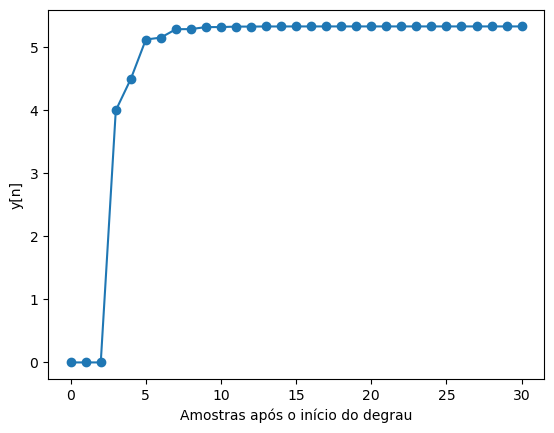

In [ ]:
import numpy as np  
import matplotlib.pyplot as plt 
import time 
  
amostras = 100  
w = np.zeros(amostras)
y = np.zeros(amostras)
x = np.ones(amostras)
x[0] = 0
x[1] = 0
x[2] = 0

inicio = time.perf_counter()

for i in range(3,amostras):
  w[i] = 4*x[i] - 0.5*x[i-1] - 0.5*x[i-2]
  y[i] = w[i] + 0.25*y[i-1] + 0.25*y[i-2] - 0.0625*y[i-3]

tempo_direta1 = time.perf_counter() - inicio
y_direta1 = y.copy()

print('Tempo da forma direta I:', tempo_direta1, 's')
plt.plot(y[0::])
plt.xlabel('Amostras após o início do degrau')
plt.ylabel('y[n]')
plt.show()

### Forma direta II

Tempo da forma direta II: 0.0003166000242345035 s


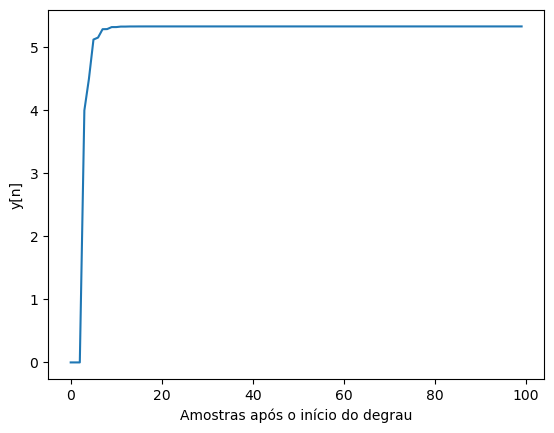

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import time

amostras = 100
w = np.zeros(amostras)
y = np.zeros(amostras)
x = np.ones(amostras)
x[0] = 0
x[1] = 0
x[2] = 0

inicio = time.perf_counter()

for i in range(0,amostras):
  w[i] = x[i] + 0.25*w[i-1] + 0.25*w[i-2] - 0.0625*w[i-3]
  y[i] = 4*w[i] - 0.5*w[i-1] - 0.5*w[i-2]

tempo_direta2 = time.perf_counter() - inicio
y_direta2 = y.copy()

print('Tempo da forma direta II:', tempo_direta2, 's')
plt.plot(y[0::])
plt.xlabel('Amostras após o início do degrau')
plt.ylabel('y[n]')
plt.show()

### Forma paralela

Tempo da forma paralela: 0.0014254309999159887 s


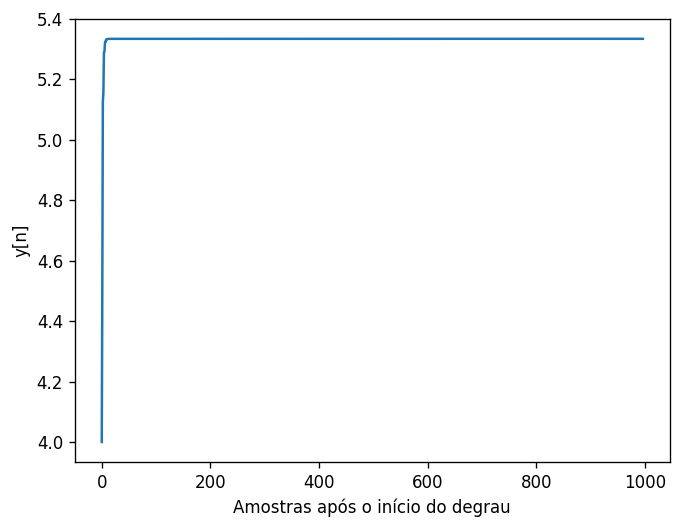

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import time

w1 = np.zeros(1000)
w2 = np.zeros(1000)
w3 = np.zeros(1000)
y = np.zeros(1000)
x = np.ones(1000)
x[0] = 0
x[1] = 0
x[2] = 0

inicio = time.perf_counter()

for i in range(3,1000):
  w1[i] = x[i] + 0.5*w1[i-1]
  w2[i] = x[i] - 0.5*w2[i-1]
  w3[i] = x[i] + 0.25*w3[i-1]
  y[i] = w1[i] + w2[i] + 2*w3[i]

tempo_paralela = time.perf_counter() - inicio
y_paralela = y.copy()

print('Tempo da forma paralela:', tempo_paralela, 's')
plt.plot(y[3::])
plt.xlabel('Amostras após o início do degrau')
plt.ylabel('y[n]')
plt.show()

### Comparação da execução atual
Execute as três células anteriores antes desta. Os tempos abaixo medem o processamento, não a duração física de um sinal.

Os valores podem mudar entre execuções, especialmente com laços curtos em um ambiente compartilhado. Repitam as três medições antes de discutir uma diferença pequena. Uma medição isolada não determina qual estrutura é sempre mais rápida. A forma paralela é uma decomposição matemática; este código executa os ramos sequencialmente, sem processamento simultâneo.

In [6]:
print('Direta I: %.6f ms' % (1000*tempo_direta1))
print('Direta II: %.6f ms' % (1000*tempo_direta2))
print('Paralela: %.6f ms' % (1000*tempo_paralela))
print('Direta I e direta II coincidem:', np.allclose(y_direta1, y_direta2))
print('Direta I e paralela coincidem:', np.allclose(y_direta1, y_paralela))

Direta I: 1.111563 ms
Direta II: 1.173095 ms
Paralela: 1.425431 ms
Direta I e direta II coincidem: True
Direta I e paralela coincidem: True


## Pontos para explicar no vídeo
- $z^{-1}$ representa uma amostra de atraso.
- Os coeficientes do denominador trocam de sinal ao isolar o estado ou a saída.
- A forma direta II compartilha os atrasos do sinal interno.
- Na cascata, a saída de uma seção alimenta a seguinte; no paralelo, todas recebem a mesma entrada e suas saídas são somadas.
- A igualdade das saídas deve ser conferida antes de comparar tempos.

As deduções completas, os diagramas e o roteiro dividido entre cinco integrantes estão no PDF de resolução. Não há valores de coeficientes inventados para o exercício 1.